# MobileRec: Dataset Analysis and Preparation for Recommender Systems

MobileRec is a publicly available dataset hosted on Hugging Face platform made for research on mobile app recommendation. It consists of user reviews collected from the Google Play Store and a separate set of app metadata.

In [1]:
from datasets import load_dataset
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

Both components of MobileRec are loaded from Hugging Face. The original data are preserved and used as the source for exploratory analysis and the preparation of working files.

In [2]:
mbr_data = load_dataset("recmeapp/mobilerec", data_dir="interactions")
mbr_meta = load_dataset("recmeapp/mobilerec", data_dir="app_meta")
interactions = mbr_data["train"]
metadata = mbr_meta["train"]

In [3]:
print(interactions)
print(metadata)

Dataset({
    features: ['app_package', 'review', 'rating', 'votes', 'date', 'uid', 'formated_date', 'unix_timestamp', 'app_category'],
    num_rows: 19297019
})
Dataset({
    features: ['app_package', 'app_name', 'developer_name', 'app_category', 'description', 'content_rating', 'num_reviews', 'price', 'avg_rating'],
    num_rows: 10173
})


In [4]:
print("Interactions dataset size: "+str(interactions.dataset_size/1000000000) + " GB")
print("Metadata dataset size: "+str(metadata.dataset_size/1000000000) + " GB")

Interactions dataset size: 4.846877772 GB
Metadata dataset size: 0.022019648 GB


The `interactions` dataset contains 19,297,019 user–app interactions and occupies approximately 4.85 GB. The much smaller `metadata` dataset occupies approximately 0.02 GB and describes 10,173 apps.

Because of its size, the interaction dataset is not loaded into a single `pandas DataFrame`. An initial sample of 10,000 rows is used for inspection, while checks across the full dataset are performed in batches to limit RAM usage.

In [5]:
sample_df = interactions.select(range(10_000)).to_pandas()
sample_df.head()

,app_package,review,rating,votes,date,uid,formated_date,unix_timestamp,app_category
0,com.cleverapps.heroes,It's really a fun game,5,1,"October 21, 2018",shqoc6X1fcJRLEmx,2018-10-21,1.540094e+09,Casual
1,com.bodyfast,uninstalling. it was ok but felt like it was c...,2,0,"January 18, 2019",shqoc6X1fcJRLEmx,2019-01-18,1.547788e+09,Health & Fitness
2,com.thrivegames.wordshapes,Love this game,4,1,"January 16, 2021",shqoc6X1fcJRLEmx,2021-01-16,1.610773e+09,Word
3,com.affinity.rewarded_play,Doesn't update play time. Just downloaded it 3...,1,1,"November 4, 2021",shqoc6X1fcJRLEmx,2021-11-04,1.635998e+09,Entertainment
4,dating.inmessage.net,app crashes every time I try to log in. what g...,1,0,"November 24, 2021",shqoc6X1fcJRLEmx,2021-11-24,1.637730e+09,Dating


In [6]:
sample_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_package     10000 non-null  object 
 1   review          10000 non-null  object 
 2   rating          10000 non-null  int64  
 3   votes           10000 non-null  int64  
 4   date            10000 non-null  object 
 5   uid             10000 non-null  object 
 6   formated_date   10000 non-null  object 
 7   unix_timestamp  10000 non-null  float64
 8   app_category    10000 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 703.3+ KB


The `interactions` dataset has nine columns. Text columns contain identifiers, dates, review text, and app categories, while `rating`, `votes`, and `unix_timestamp` are numeric.

The `app_package` column identifies each app and links interactions to app metadata. The `uid` column contains anonymized user identifiers. Each row represents one review that a user submitted for an app. `rating` is the user-assigned score from one to five, `votes` counts helpfulness votes, and `app_category` identifies the app category.

The `date`, `formated_date`, and `unix_timestamp` columns represent the date of the same interaction in different formats.

In [7]:
date_columns = ["date", "formated_date", "unix_timestamp", "uid"]
sample_df[date_columns].head(10)

,date,formated_date,unix_timestamp,uid
0,"October 21, 2018",2018-10-21,1.540094e+09,shqoc6X1fcJRLEmx
1,"January 18, 2019",2019-01-18,1.547788e+09,shqoc6X1fcJRLEmx
2,"January 16, 2021",2021-01-16,1.610773e+09,shqoc6X1fcJRLEmx
3,"November 4, 2021",2021-11-04,1.635998e+09,shqoc6X1fcJRLEmx
4,"November 24, 2021",2021-11-24,1.637730e+09,shqoc6X1fcJRLEmx
5,"March 20, 2015",2015-03-20,1.426824e+09,smlNgCSD1z66dtpP
6,"March 28, 2015",2015-03-28,1.427515e+09,smlNgCSD1z66dtpP
7,"May 9, 2017",2017-05-09,1.494302e+09,smlNgCSD1z66dtpP
8,"August 3, 2019",2019-08-03,1.564805e+09,smlNgCSD1z66dtpP
9,"May 8, 2021",2021-05-08,1.620446e+09,smlNgCSD1z66dtpP


The `date` column stores the date as text, while `formated_date` uses the readable `YYYY-MM-DD` format. The `unix_timestamp` column represents the same date as the number of seconds since January 1, 1970. In this dataset, timestamps have day-level resolution and do not specify the time of day.

The following checks verify that these date representations agree. `unix_timestamp` is used to order interactions chronologically, while `formated_date` is retained for readability.

In [8]:
metadata_df = metadata.to_pandas()
metadata_df.head()

,app_package,app_name,developer_name,app_category,description,content_rating,num_reviews,price,avg_rating
0,com.natewren.lines,Lines Pro - Icon Pack,Nate Wren Design,Personalization,Lines icons (pro version) are outlined shapes ...,Everyone,"2,997",$1.99 Buy,4.7
1,com.capitalone.credittracker,CreditWise from Capital One,"Capital One Services, LLC",Finance,Know your credit score and much more\n\nCapita...,Everyone,"94,914",Install,4.7
2,com.purascents.android,Pura - Smart Fragrance Dispenser,Pura,House & Home,Pura is a smart home fragrance device that you...,Everyone,778,Install,4.4
3,com.wallethub.mywallet,"WalletHub - Free Credit Score, Report & Monito...",WalletHub,Finance,WalletHub is the first app to offer 100% free ...,Everyone,"7,025",Install,4.7
4,air.com.samuramu.gg.se,#SelfLove (GG Confidence & Self esteem),Ggtude Ltd,Medical,Wish to build confidence and have higher self ...,Everyone,625,Install,4.1


In [9]:
metadata_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10173 entries, 0 to 10172
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_package     10173 non-null  object 
 1   app_name        10173 non-null  object 
 2   developer_name  10173 non-null  object 
 3   app_category    10173 non-null  object 
 4   description     10173 non-null  object 
 5   content_rating  10173 non-null  object 
 6   num_reviews     10173 non-null  object 
 7   price           10173 non-null  object 
 8   avg_rating      10173 non-null  float64
dtypes: float64(1), object(8)
memory usage: 715.4+ KB


The `metadata` dataset contains one row per app. It includes the app identifier and name, developer name, category, description, content rating, price, global review count, and global average rating.

The `app_package` column uniquely identifies each app and should match the corresponding column in `interactions`. The formats of `price`, `num_reviews`, and `avg_rating` require additional checks before the prepared metadata are saved.

## Analysis and Cleaning of the `interactions` Dataset

The `interactions` dataset contains more than 19 million rows, so full-dataset checks are performed in batches. Only one batch is loaded into memory at a time, and the results are aggregated across batches.

The first check identifies standard missing values.

In [10]:
missing_values_counts = pd.Series(0, index = interactions.column_names)
batch_size = 100000

for batch in interactions.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    missing_values_counts+= batch_df.isna().sum()

missing_values_counts

app_package          0
review            1206
rating               0
votes                0
date                 0
uid                  0
formated_date        0
unix_timestamp       0
app_category         0
dtype: int64

The full dataset contains 1,206 standard missing values, all in the `review` column. Review text analysis is outside the scope of this study, so `review` is excluded from the working interaction dataset. This step does not modify the original dataset.

In [11]:
inter_data = interactions.select_columns(["uid", "app_package", "date", "formated_date","unix_timestamp", "rating", "votes", "app_category"])

print(inter_data)

Dataset({
    features: ['uid', 'app_package', 'date', 'formated_date', 'unix_timestamp', 'rating', 'votes', 'app_category'],
    num_rows: 19297019
})


No standard missing values (`NaN`, `None`, or `NA`) were found in the remaining columns. The next check looks for text values that appear populated but contain no useful information, such as empty strings or whitespace.

In [12]:
text_missing_values_counts = pd.Series(0,index=["app_package", "uid", "date", "formated_date", "app_category"] )

batch_size = 100000
missing_values = ["","na","n/a","null","-", "--","---",".","..","...",  "/","//"]

for batch in inter_data.iter( batch_size=batch_size):
    batch_df= pd.DataFrame(batch)
    for column in ["app_package", "uid", "date", "formated_date", "app_category"]:
        text = batch_df[column].astype("string").str.strip().str.lower()
        text_missing_values_counts[column] += text.isin(missing_values).sum()


text_missing_values_counts

app_package      0
uid              0
date             0
formated_date    0
app_category     0
dtype: int64

No empty strings, whitespace-only values, or common textual missing-value markers were found in the text columns. The next checks examine the valid rating range and the values in `votes`.

In [13]:
sample_df["rating"].value_counts().sort_index()

rating
1    2123
2    1259
3    1508
4    1953
5    3157
Name: count, dtype: int64

In [14]:
rating_counts = Counter()
valid_ratings=[1,2,3,4,5]
invalid_ratings_num = 0
batch_size=100000

for batch in inter_data.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    ratings = batch_df["rating"]
    rating_counts.update(ratings)
    invalid_ratings_num+=(~ratings.isin(valid_ratings)).sum()

distribution = pd.Series(rating_counts).sort_index()
summary = pd.DataFrame({"counts:": distribution, "percetage:":(distribution/distribution.sum()*100).round(2)})

summary

,counts:,percetage:
1,4068183,21.08
2,2441008,12.65
3,2919802,15.13
4,3744068,19.40
5,6123958,31.74


The `rating` column contains only valid scores from one to five. Five-star ratings are the most frequent, accounting for 31.74% of interactions, while two-star ratings are the least frequent at 12.65%.

This distribution describes only the reviews collected in MobileRec and does not represent all Google Play users. Ratings are retained in the final file, but no interactions are discarded based on their rating.

In [15]:
sample_df["votes"].value_counts().sort_index()

votes
0       6225
1       1198
2        523
3        314
4        220
        ... 
1136       1
1378       1
1908       1
2491       1
3463       1
Name: count, Length: 233, dtype: int64

In [16]:
negative_votes = 0
zero_votes = 0
min_votes=None
max_votes=None
batch_size = 100000

for batch in inter_data.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    votes=batch_df["votes"]
    negative_votes+=(votes<0).sum()
    zero_votes+=(votes==0).sum()
    c_min=votes.min()
    c_max=votes.max()
    
    if min_votes is None or c_min < min_votes:
      min_votes = c_min
    if max_votes is None or c_max > max_votes:
        max_votes = c_max

print("Minimum vote count: ", min_votes)
print("Maximum vote count: ", max_votes)
print("Reviews with 0 votes: ", zero_votes)
print("Reviews with a negative vote count: ", negative_votes)

Minimum vote count:  0
Maximum vote count:  193537
Reviews with 0 votes:  11878924
Reviews with a negative vote count:  0


The `votes` column contains no negative values. Values range from zero to 193,537, and 11,878,924 reviews have no helpfulness votes.

This attribute records how many other users marked a review as helpful. Since review text is excluded from the working interaction dataset, the `votes` column is also removed.

In [17]:
inter_data= inter_data.remove_columns("votes")
print(inter_data)

Dataset({
    features: ['uid', 'app_package', 'date', 'formated_date', 'unix_timestamp', 'rating', 'app_category'],
    num_rows: 19297019
})


In [18]:
sample_df[date_columns[0:3]].head(10)

,date,formated_date,unix_timestamp
0,"October 21, 2018",2018-10-21,1.540094e+09
1,"January 18, 2019",2019-01-18,1.547788e+09
2,"January 16, 2021",2021-01-16,1.610773e+09
3,"November 4, 2021",2021-11-04,1.635998e+09
4,"November 24, 2021",2021-11-24,1.637730e+09
5,"March 20, 2015",2015-03-20,1.426824e+09
6,"March 28, 2015",2015-03-28,1.427515e+09
7,"May 9, 2017",2017-05-09,1.494302e+09
8,"August 3, 2019",2019-08-03,1.564805e+09
9,"May 8, 2021",2021-05-08,1.620446e+09


Three columns describe the interaction date. `date` and `formated_date` store the same date as text, while `unix_timestamp` provides a numeric representation.

The redundant `date` column is removed. `formated_date` is retained for readability, and `unix_timestamp` is used to verify and establish chronological order before the training, validation, and test split.

In [19]:
inter_data= inter_data.remove_columns("date")
print(inter_data)

Dataset({
    features: ['uid', 'app_package', 'formated_date', 'unix_timestamp', 'rating', 'app_category'],
    num_rows: 19297019
})


In [20]:
invalid_dates = 0
min_date = None
max_date = None
batch_size = 100000

for batch in inter_data.iter(batch_size=batch_size):
  batch_df = pd.DataFrame(batch)
  dates = pd.to_datetime(batch_df["formated_date"], format="%Y-%m-%d", errors="coerce")
  invalid_dates += dates.isna().sum()
  c_min = dates.min()
  c_max = dates.max()

  if min_date is None or c_min < min_date:
      min_date = c_min

  if max_date is None or c_max > max_date:
      max_date = c_max

print("Najraniji datum:", min_date.date())
print("Najkasniji datum:", max_date.date())
print("Invalidly formatted dates:", invalid_dates)

Najraniji datum: 2012-11-15
Najkasniji datum: 2022-04-14
Invalidly formatted dates: 0


In [21]:
invalid_time = 0
negative_zero_time = 0
min_time = None
max_time = None
batch_size = 100000

for batch in inter_data.iter(batch_size=batch_size):
  batch_df = pd.DataFrame(batch)
  time = batch_df["unix_timestamp"]
  dates = pd.to_datetime(time, unit="s",utc=True,errors="coerce")
  invalid_time += dates.isna().sum()
  negative_zero_time += (time <= 0).sum()
  valid_dates = dates.dropna()

  if not valid_dates.empty:
      c_min = valid_dates.min()
      c_max = valid_dates.max()
      if min_time is None or c_min < min_time:
          min_time = c_min
      if max_time is None or c_max > max_time:
          max_time = c_max

print("Najraniji datum:", min_time)
print("Najkasniiji datum:", max_time)
print("Invalid values:", invalid_time)
print("Zero or negative values:", negative_zero_time)

Najraniji datum: 2012-11-15 05:00:00+00:00
Najkasniiji datum: 2022-04-14 04:00:00+00:00
Invalid values: 0
Zero or negative values: 0


In [22]:
correct_dates = 0
incorrect_dates = 0
batch_size = 100000

for batch in inter_data.iter(batch_size=batch_size):
  batch_df = pd.DataFrame(batch)
  dates_unix = pd.to_datetime(batch_df["unix_timestamp"],unit="s",utc=True,errors="coerce" ).dt.date
  dates_text = pd.to_datetime(batch_df["formated_date"],format="%Y-%m-%d", errors="coerce").dt.date
  dates_match = dates_unix == dates_text
  correct_dates += dates_match.sum()
  incorrect_dates += (~dates_match).sum()

print("Matching dates:", correct_dates)
print("Non-matching dates:", incorrect_dates)

Matching dates: 19297019
Non-matching dates: 0


All values in `formated_date` can be parsed as dates. Dates derived from `unix_timestamp` match them in all 19,297,019 rows, with no date inconsistencies detected.

In [23]:
num_interactions = len(inter_data)
num_users = len(inter_data.unique("uid"))
num_apps = len(inter_data.unique("app_package"))
num_categories = len(inter_data.unique("app_category"))

overview = pd.Series({
    "interactions": num_interactions,
    "users": num_users,
    "applications": num_apps,
    "kategorije": num_categories
})

overview

interactions    19297019
users             700111
applications       10173
kategorije            48
dtype: int64

The `interactions` dataset contains 19,297,019 reviews, 700,111 distinct users, and 10,173 distinct apps across 48 categories. The following analysis examines how interactions are distributed across users, apps, and categories.

In [24]:
num_users=Counter()
batch_size=100000
for batch in inter_data.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    num_users.update(batch_df["uid"])

In [25]:
user_counts = pd.Series(num_users)
user_counts.describe()

count    700111.000000
mean         27.562799
std          42.043285
min           5.000000
25%           6.000000
50%           8.000000
75%          25.000000
max         253.000000
dtype: float64

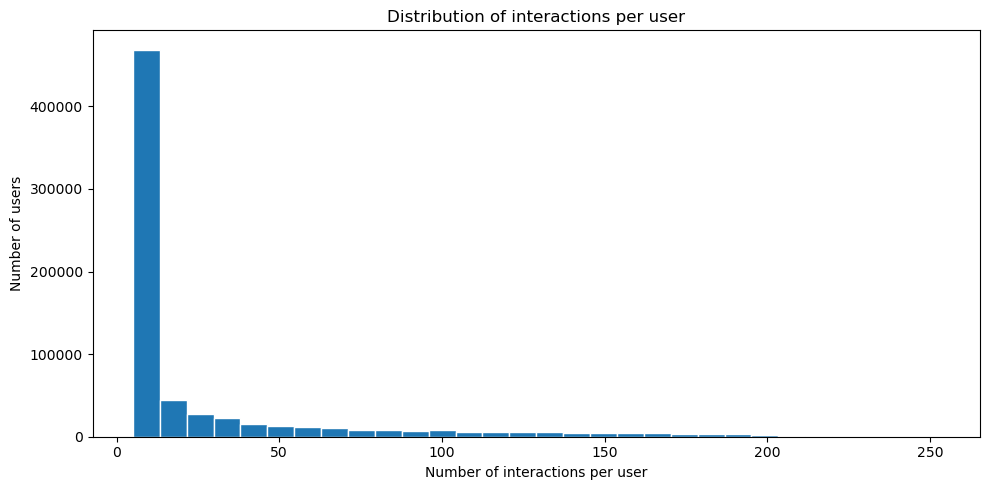

In [26]:
plt.figure(figsize=(10, 5))

plt.hist(user_counts, bins=30, edgecolor="white")

plt.xlabel("Number of interactions per user")
plt.ylabel("Number of users")
plt.title("Distribution of interactions per user")

plt.tight_layout()
plt.show()

Every user has at least five interactions. The median history length is eight, the mean is 27.56, and the maximum is 253.

The difference between the median and mean indicates that most users have relatively short histories, while a smaller group has substantially more interactions. Subsequent evaluation should therefore retain users with different history lengths rather than focus only on the most active users.

In [27]:
app_counts = Counter()
batch_size = 100000
for batch in inter_data.iter(batch_size=batch_size):
  batch_df = pd.DataFrame(batch)
  app_counts.update(batch_df["app_package"])

In [28]:
app_counts = pd.Series(app_counts)
app_counts.describe()

count    10173.000000
mean      1896.885776
std       1742.762629
min         18.000000
25%        341.000000
50%       1411.000000
75%       3101.000000
max      14345.000000
dtype: float64

In [29]:
top_apps = app_counts.sort_values(ascending=False).head(20)
top_apps = top_apps.reset_index()
top_apps.columns = ["app_package", "interaction_count"]

top_apps = top_apps.merge(
    metadata_df[["app_package", "app_name"]], on="app_package",how="left")

top_apps["app_label"] = top_apps["app_name"].fillna(top_apps["app_package"])
top_apps

,app_package,interaction_count,app_name,app_label
0,com.snapchat.android,14345,Snapchat,Snapchat
1,com.facebook.lite,12836,Facebook Lite,Facebook Lite
2,com.lemon.lvoverseas,12187,CapCut - Video Editor,CapCut - Video Editor
3,com.king.candycrushsaga,12152,Candy Crush Saga,Candy Crush Saga
4,com.zhiliaoapp.musically,11613,TikTok,TikTok
5,com.instagram.android,11534,Instagram,Instagram
6,us.zoom.videomeetings,10904,ZOOM Cloud Meetings,ZOOM Cloud Meetings
7,com.king.candycrushsodasaga,10316,Candy Crush Soda Saga,Candy Crush Soda Saga
8,com.google.android.youtube,10161,YouTube,YouTube
9,com.squareup.cash,10145,Cash App,Cash App


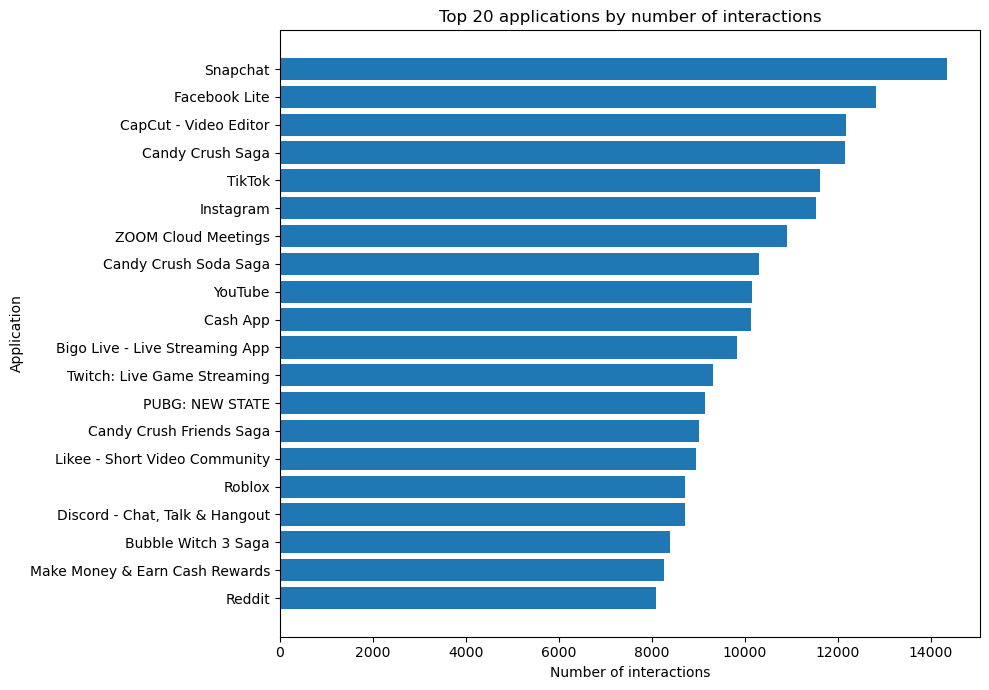

In [30]:
top_apps = top_apps.sort_values("interaction_count")
plt.figure(figsize=(10, 7))
plt.barh(top_apps["app_label"],top_apps["interaction_count"])

plt.xlabel("Number of interactions")
plt.ylabel("Application")
plt.title("Top 20 applications by number of interactions")

plt.tight_layout()
plt.show()

Apps are identified by `app_package`. The number of interactions per app ranges from 18 to 14,345, with a median of 1,411.

The distribution shows that interactions are concentrated among a relatively small number of popular apps. These apps provide more training examples, while apps in the long tail have fewer observed interactions.

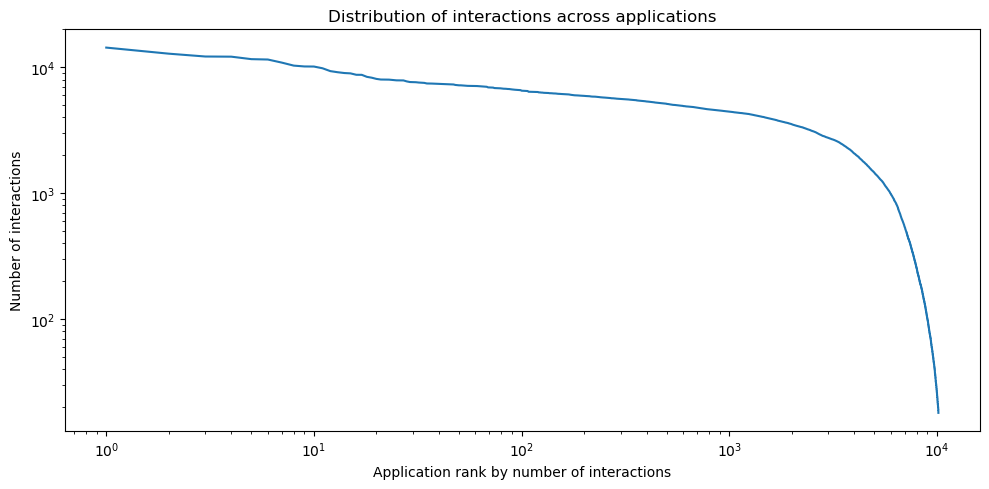

In [31]:
app_counts_desc = app_counts.sort_values(ascending=False)
app_rank = range(1, len(app_counts_desc) + 1)

plt.figure(figsize=(10, 5))
plt.plot(app_rank, app_counts_desc.values)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Application rank by number of interactions")
plt.ylabel("Number of interactions")
plt.title("Distribution of interactions across applications")

plt.tight_layout()
plt.show()

The linear-scale plot highlights the small number of apps with very large interaction counts. The logarithmic scale makes the long tail of the distribution easier to inspect.

This distribution motivates the inclusion of a Popularity baseline to measure how much recommendation performance can be achieved using global app interaction counts alone.

In [32]:
category_counts = Counter()
batch_size = 100000
for batch in inter_data.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    category_counts.update(batch_df["app_category"])

category_summary = (pd.Series(category_counts).sort_values(ascending=False))

category_summary

Action                     1373484
Role Playing               1321861
Simulation                 1023366
Strategy                    963360
Puzzle                      954909
Casual                      915267
Finance                     677697
Sports                      623334
Adventure                   613313
Shopping                    576137
Productivity                567171
Arcade                      556179
Tools                       525550
Entertainment               520505
Education                   458729
Casino                      449420
Music & Audio               444844
Communication               423351
Health & Fitness            382312
Racing                      380857
Social                      356333
Business                    347573
Travel & Local              342243
Lifestyle                   340585
Dating                      329057
Food & Drink                313340
Educational                 308817
Photography                 307177
Medical             

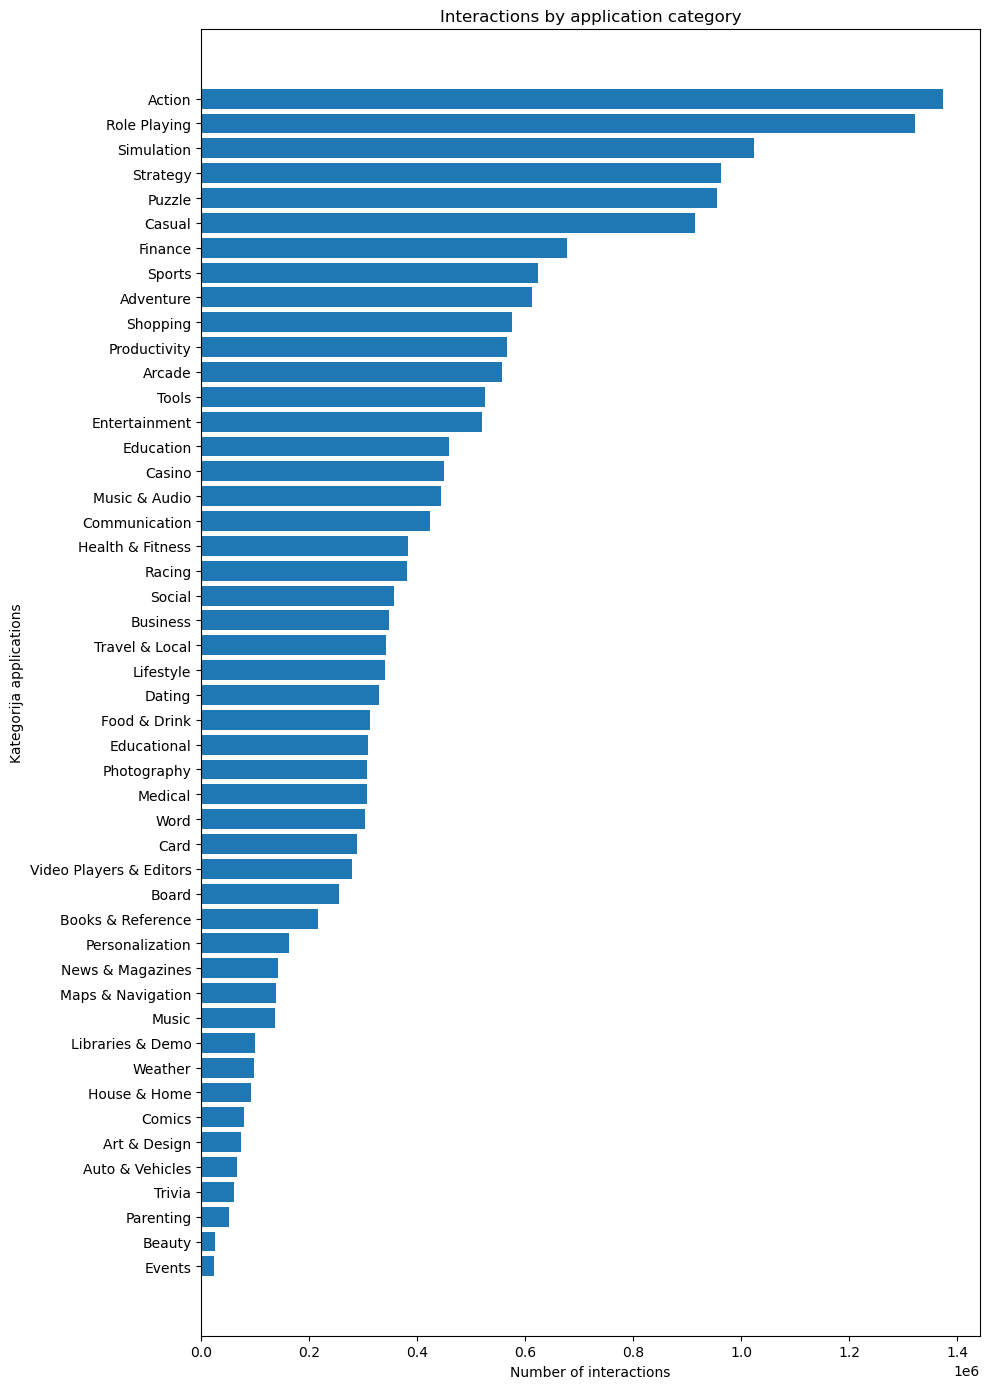

In [33]:
category_counts = pd.Series(category_counts)
category_counts = category_counts.sort_values(ascending=False)

plt.figure(figsize=(10, 14))
plt.barh(category_counts.index,category_counts.values)
plt.gca().invert_yaxis()

plt.xlabel("Number of interactions")
plt.ylabel("Kategorija applications")
plt.title("Interactions by application category")

plt.tight_layout()
plt.show()

All 48 categories have recorded interactions, but their frequencies vary considerably. `Action`, `Role Playing`, and `Simulation` are the most frequent categories, while `Events` and `Beauty` have the fewest interactions.

These differences show that some categories provide substantially more examples than others. App category remains useful for describing the dataset and for subsequent analysis of model performance by category.

In [34]:
monthly_counts = Counter()
batch_size = 100000

for batch in inter_data.iter(batch_size=batch_size):
  batch_df = pd.DataFrame(batch)
  months = batch_df["formated_date"].str[:7]
  monthly_counts.update(months)

monthly_counts = pd.Series(monthly_counts)
monthly_counts.index = pd.to_datetime(monthly_counts.index,format="%Y-%m")
monthly_counts = monthly_counts.sort_index()

monthly_counts

2012-11-01        254
2012-12-01       4405
2013-01-01       4862
2013-02-01       3827
2013-03-01       4522
               ...   
2021-12-01     871557
2022-01-01    1149725
2022-02-01    1291384
2022-03-01    1939121
2022-04-01     196745
Length: 114, dtype: int64

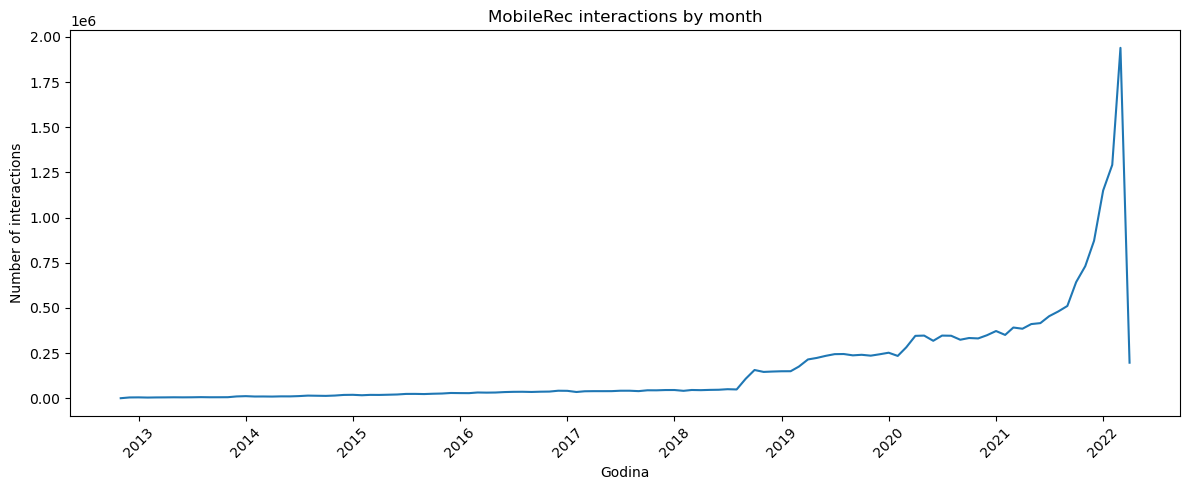

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_counts.index,monthly_counts.values)

plt.xlabel("Godina")
plt.ylabel("Number of interactions")
plt.title("MobileRec interactions by month")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The recorded dates range from November 2012 to April 2022. Interaction counts are low in the earlier years, rise after 2018, and show a pronounced increase in early 2022.

The plot reflects the reviews included in MobileRec and the dataset collection process, rather than the complete behavior of all Google Play users. Changes over time provide further motivation for a chronological rather than random data split.

## Analysis and Cleaning of App Metadata

In [36]:
metadata_df.head()

,app_package,app_name,developer_name,app_category,description,content_rating,num_reviews,price,avg_rating
0,com.natewren.lines,Lines Pro - Icon Pack,Nate Wren Design,Personalization,Lines icons (pro version) are outlined shapes ...,Everyone,"2,997",$1.99 Buy,4.7
1,com.capitalone.credittracker,CreditWise from Capital One,"Capital One Services, LLC",Finance,Know your credit score and much more\n\nCapita...,Everyone,"94,914",Install,4.7
2,com.purascents.android,Pura - Smart Fragrance Dispenser,Pura,House & Home,Pura is a smart home fragrance device that you...,Everyone,778,Install,4.4
3,com.wallethub.mywallet,"WalletHub - Free Credit Score, Report & Monito...",WalletHub,Finance,WalletHub is the first app to offer 100% free ...,Everyone,"7,025",Install,4.7
4,air.com.samuramu.gg.se,#SelfLove (GG Confidence & Self esteem),Ggtude Ltd,Medical,Wish to build confidence and have higher self ...,Everyone,625,Install,4.1


In [37]:
metadata_df.dtypes

app_package        object
app_name           object
developer_name     object
app_category       object
description        object
content_rating     object
num_reviews        object
price              object
avg_rating        float64
dtype: object

In [38]:
missing_values=metadata_df.isna().sum()
missing_data_sum=pd.DataFrame({"nedostajuce vrednosti: ": missing_values, "procenat: ": (missing_values/len(metadata_df)*100).round(2)})
missing_data_sum

,nedostajuce vrednosti:,procenat:
app_package,0,0.0
app_name,0,0.0
developer_name,0,0.0
app_category,0,0.0
description,0,0.0
content_rating,0,0.0
num_reviews,0,0.0
price,0,0.0
avg_rating,0,0.0


No standard missing values (`NaN`, `NA`, or `None`) were found in `metadata`. The next check examines text columns for potentially uninformative values.

In [39]:
metadata_text_columns = metadata_df.select_dtypes(include="object").columns
missing_text = ["", "na", "n/a", "none", "null", "nan", "-", "--", "---", ".", "..", "...", "/", "//", "unknown", "not available"]
text_missing = pd.Series(0, index=metadata_text_columns)

for col in metadata_text_columns:
    text = metadata_df[col].astype("string").str.strip().str.lower()
    text_missing[col] = text.isin(missing_text).sum()

text_missing

app_package       0
app_name          0
developer_name    0
app_category      0
description       0
content_rating    0
num_reviews       0
price             0
dtype: int64

No empty strings, whitespace-only values, or common markers such as `null` and `unknown` were found in the text columns. No apps are removed from the metadata on this basis.

In [40]:
app_sum = pd.Series({
    "Number of rows": len(metadata_df),
    "Jedinstveni app_package": metadata_df["app_package"].nunique(),
    "Dupli app_package": metadata_df["app_package"].duplicated().sum()
})
app_sum

Number of rows             10173
Jedinstveni app_package    10173
Dupli app_package              0
dtype: int64

In [41]:
inter_apps = set(inter_data.unique("app_package"))
meta_apps = set(metadata_df["app_package"])

missing_meta = inter_apps - meta_apps
missing_inter = meta_apps - inter_apps

match_summary = pd.Series({
    "Applications in interactions": len(inter_apps),
    "Applications in metadata": len(meta_apps),
    "Applications without metadata": len(missing_meta),
    "Metadata applications bez interakcija": len(missing_inter),
    "Ukupni %": round((len(inter_apps) - len(missing_meta)) / len(inter_apps) * 100, 2)
})
match_summary

Applications in interactions             10173.0
Applications in metadata                 10173.0
Applications without metadata                0.0
Metadata applications bez interakcija        0.0
Ukupni %                                   100.0
dtype: float64

Each app in the metadata has a unique `app_package` value. All 10,173 apps in the metadata also appear in the interaction dataset, and every app in the interactions has a corresponding metadata row.

The two datasets can therefore be joined on `app_package` without unmatched apps.

In [42]:
for col in ["app_category", "content_rating", "price"]:
    print("\n" + col)
    print("number of distinct values:", metadata_df[col].nunique())
    print(metadata_df[col].value_counts().head(15))


app_category
number of distinct values: 48
app_category
Role Playing    658
Simulation      537
Puzzle          537
Action          529
Strategy        520
Casual          432
Education       429
Medical         422
Educational     420
Adventure       397
Sports          289
Arcade          264
Productivity    260
Finance         254
Dating          234
Name: count, dtype: int64

content_rating
number of distinct values: 5
content_rating
Everyone           6841
Teen               1925
Everyone 10+        891
Mature 17+          501
Adults only 18+      15
Name: count, dtype: int64

price
number of distinct values: 83
price
Install      9016
$2.99 Buy     182
$4.99 Buy     161
$0.99 Buy     135
$3.99 Buy     135
$1.99 Buy     111
$6.99 Buy      59
$9.99 Buy      52
$5.99 Buy      43
$3.49 Buy      27
$2.49 Buy      26
$1.49 Buy      20
$7.99 Buy      18
$4.49 Buy      15
$5.49 Buy      15
Name: count, dtype: int64


In [43]:
valid_price = metadata_df["price"].str.fullmatch(r"Install|\$\d+\.\d{2} Buy")

price_summary = pd.Series({
    "Install:": metadata_df["price"].eq("Install").sum(),
    "placene: ": metadata_df["price"].str.endswith("Buy").sum(),
    "neocekivan format:": (~valid_price).sum()
})
price_summary

Install:              9016
placene:              1143
neocekivan format:      26
dtype: int64

In [44]:
metadata_df.loc[~valid_price, "price"].value_counts()

price
$0.99 Install      7
not found          3
$1.99 $0.49 Buy    2
$3.49 $1.99 Buy    1
$9.99 Install      1
$8.99 $6.29 Buy    1
$0.99 $0.49 Buy    1
$3.49 Install      1
$1.99 Install      1
$8.99 $2.49 Buy    1
$6.99 $2.99 Buy    1
$3.99 $2.49 Buy    1
$3.99 Install      1
$1.99 $0.99 Buy    1
$3.99 $0.99 Buy    1
$4.99 $1.99 Buy    1
$2.99 $0.99 Buy    1
Name: count, dtype: int64

The `price` column combines installation labels and monetary values. Two columns are derived from it: `has_price`, which indicates whether an app is listed as paid, and `price_usd`, which stores its numeric price in US dollars.

Some values differ from the expected `Install` and `$amount Buy` formats. Prices therefore require careful interpretation: they describe the metadata snapshot collected for the dataset, not the historical price at the time of each review.

In [45]:
metadata_df["avg_rating"].describe()

count    10173.000000
mean         4.200020
std          0.561826
min          0.000000
25%          4.000000
50%          4.300000
75%          4.500000
max          5.000000
Name: avg_rating, dtype: float64

In [46]:
invaild = ((metadata_df["avg_rating"] < 0) | (metadata_df["avg_rating"] > 5)).sum()
zero = metadata_df["avg_rating"].eq(0)

avg_summary = pd.Series({
    "nedozvoljene ocene: ": invaild,
    "prosecna ocena 0:": zero.sum(),
    "rating = 0 and review count = 0: ": ((zero) & (metadata_df["num_reviews"] == "0")).sum(),
    "rating = 0 and review count is not 0: ": ((zero) & (metadata_df["num_reviews"] != "0")).sum()
})
avg_summary

nedozvoljene ocene:                        0
prosecna ocena 0:                         50
rating = 0 and review count = 0:          44
rating = 0 and review count is not 0:      6
dtype: int64

In [47]:
metadata_df.loc[zero, ["app_name", "num_reviews", "avg_rating"]].head(10)

,app_name,num_reviews,avg_rating
191,Motorgy - Buy & Sell Cars in Kuwait,0,0.0
776,Zeno Health - Generic Pharmacy,0,0.0
997,Forma Ideale,0,0.0
1031,Nordic Choice Hotels,0,0.0
1230,Ninja Superhero Rings Warrior,0,0.0
1386,Grays,0,0.0
1403,Big Boy Toyz,0,0.0
1543,International Space Station Tour VR,0,0.0
1621,Kavtek: AR Home Design,0,0.0
1720,Speedy - Card Game 3D / AR,0,0.0


In [48]:
zero_apps = metadata_df.loc[
    (metadata_df["avg_rating"] == 0) & (metadata_df["num_reviews"] == "0"),
    "app_package"
]

zero_interactions = Counter()
batch_size=100000

for batch in inter_data.iter(batch_size=batch_size):
    batch_df = pd.DataFrame(batch)
    apps = batch_df.loc[batch_df["app_package"].isin(zero_apps), "app_package"]
    zero_interactions.update(apps)

zero_check = metadata_df.loc[
    (metadata_df["avg_rating"] == 0) & (metadata_df["num_reviews"] == "0"),
    ["app_name", "app_package", "num_reviews", "avg_rating"]
].copy()

zero_check["interactions"] = zero_check["app_package"].map(zero_interactions).fillna(0).astype(int)

zero_summary = pd.Series({
    "applications bez globalnih recenzija:": len(zero_check),
    "applications sa MobileRec interakcijama:": (zero_check["interactions"] > 0).sum(),
    "minimum MobileRec interactions:": zero_check["interactions"].min(),
    "maximum MobileRec interactions:": zero_check["interactions"].max()
})

zero_summary


applications bez globalnih recenzija:         44
applications sa MobileRec interakcijama:      44
minimum MobileRec interactions:               18
maximum MobileRec interactions:             1134
dtype: int64

The `avg_rating` column represents the average rating reported by Google Play, rather than the average computed from MobileRec interactions. Fifty apps have a value of zero. Of these, 44 also have `num_reviews = 0`, while the remaining six have a reported global review count.

Zero is therefore treated as a missing value in `avg_rating_clean`, rather than as the lowest average rating. A separate column, `has_average_rating`, records whether an average rating is available. All 44 apps with no reported global reviews nevertheless have between 18 and 1,134 MobileRec interactions. This inconsistency indicates that the global aggregates cannot be treated as a direct summary of the collected interactions.

In [49]:
valid_reviews = metadata_df["num_reviews"].str.fullmatch(r"0|[1-9]\d{0,2}(,\d{3})*")
valid_reviews.value_counts()

num_reviews
True    10173
Name: count, dtype: int64

In [50]:
num_rev = pd.to_numeric(metadata_df["num_reviews"].str.replace(",", "", regex=False))
num_rev.describe()

count    1.017300e+04
mean     3.881984e+05
std      3.507690e+06
min      0.000000e+00
25%      2.535000e+03
50%      1.618000e+04
75%      9.533100e+04
max      1.578377e+08
Name: num_reviews, dtype: float64

The `num_reviews` column represents the global review count for each app, not just the reviews included in MobileRec. Commas are removed before conversion to the numeric column `num_reviews_int`.

The median is 16,180 reviews, with some apps having substantially larger counts. Like price and average rating, this value is an aggregate from the metadata collection snapshot, not a historical value associated with each interaction.

In [51]:
p_type = metadata_df["price"].str.extract(r"(Install|Buy)$", expand=False)
metadata_df["has_price"] = p_type.map({"Install": False, "Buy": True}).astype("boolean")
metadata_df["price_usd"] = metadata_df["price"].str.extract(r"\$(\d+\.\d{2})\s+Buy$", expand=False)
metadata_df.loc[p_type == "Install", "price_usd"] = 0
metadata_df["price_usd"] = pd.to_numeric(metadata_df["price_usd"], errors="coerce")

metadata_df["num_reviews_int"] = pd.to_numeric(metadata_df["num_reviews"].str.replace(",", "", regex=False)).astype("Int64")

metadata_df.loc[
    (metadata_df["avg_rating"] == 0) & (metadata_df["num_reviews"] == "0"),
    "num_reviews_int"
] = pd.NA
metadata_df["avg_rating_clean"] = metadata_df["avg_rating"]
metadata_df.loc[metadata_df["avg_rating_clean"] == 0, "avg_rating_clean"] = pd.NA
metadata_df["has_average_rating"] = metadata_df["avg_rating"] > 0

metadata_df = metadata_df.drop(columns=["price", "num_reviews", "avg_rating"])
metadata_df.head()

,app_package,app_name,developer_name,app_category,description,content_rating,has_price,price_usd,num_reviews_int,avg_rating_clean,has_average_rating
0,com.natewren.lines,Lines Pro - Icon Pack,Nate Wren Design,Personalization,Lines icons (pro version) are outlined shapes ...,Everyone,True,1.99,2997,4.7,True
1,com.capitalone.credittracker,CreditWise from Capital One,"Capital One Services, LLC",Finance,Know your credit score and much more\n\nCapita...,Everyone,False,0.00,94914,4.7,True
2,com.purascents.android,Pura - Smart Fragrance Dispenser,Pura,House & Home,Pura is a smart home fragrance device that you...,Everyone,False,0.00,778,4.4,True
3,com.wallethub.mywallet,"WalletHub - Free Credit Score, Report & Monito...",WalletHub,Finance,WalletHub is the first app to offer 100% free ...,Everyone,False,0.00,7025,4.7,True
4,air.com.samuramu.gg.se,#SelfLove (GG Confidence & Self esteem),Ggtude Ltd,Medical,Wish to build confidence and have higher self ...,Everyone,False,0.00,625,4.1,True


The prepared metadata retain descriptive columns for analysis, while price, global review count, and global average rating are converted into more suitable numeric and Boolean attributes. The original `price`, `num_reviews`, and `avg_rating` columns are replaced by their processed versions.

In [52]:
metadata_summary = pd.Series({
    "number of applications:": len(metadata_df),
    "number of columns": len(metadata_df.columns),
    "besplatne applications: ": (metadata_df["has_price"] == False).sum(),
    "placene applications: ": (metadata_df["has_price"] == True).sum(),
    "nepoznata cena:": metadata_df["has_price"].isna().sum(),
    "ocene 0 pretvorene u NA:": metadata_df["avg_rating_clean"].isna().sum()
})
metadata_summary

number of applications:     10173
number of columns              11
besplatne applications:      9027
placene applications:        1143
nepoznata cena:                 3
ocene 0 pretvorene u NA:       50
dtype: int64

In [53]:
inter_data = inter_data.remove_columns("app_category")

The `app_category` column appears in both datasets with the same meaning. It is removed from the working interaction dataset to avoid storing duplicate information and retained in the app metadata.

In [54]:
developer_count = metadata_df["developer_name"].value_counts()
one_app_developers = developer_count.eq(1)

developer_sum = pd.Series({
    "Razliciti developeri:": developer_count.size,
    "Minimum number of applications per developer:": developer_count.min(),
    "Maximum number of applications per developer:": developer_count.max(),
    "Developeri sa jednom aplikacijom:": one_app_developers.sum(),
    "Udeo takvih developera (%):": round(one_app_developers.mean() * 100, 2),
    "Applications from such developers:": one_app_developers.sum(),
    "Share of such applications (%):": round(one_app_developers.sum() / len(metadata_df) * 100, 2)
})
developer_sum


Razliciti developeri:                            6235.00
Minimum number of applications per developer:       1.00
Maximum number of applications per developer:      74.00
Developeri sa jednom aplikacijom:                4908.00
Udeo takvih developera (%):                        78.72
Applications from such developers:               4908.00
Share of such applications (%):                    48.25
dtype: float64

The dataset contains 6,235 distinct developers. Of these, 4,908 have only one app, representing 78.72% of developers and 48.25% of apps.

The large proportion of developers with a single app limits the usefulness of `developer_name` for identifying similarities across many apps. The column is nevertheless retained as descriptive metadata and for potential further analysis.

## Saving the Prepared Data

The processed datasets are saved in `Parquet` format, which supports compression and selective column loading. Both are useful for a dataset with more than 19 million rows.

The final interaction file contains the columns needed for the chronological split and subsequent processing: `uid`, `app_package`, `formated_date`, `unix_timestamp`, and `rating`. The original MobileRec dataset is preserved as an unchanged source.

In [55]:
from pathlib import Path
import pyarrow.parquet as pq

final_dir = Path("artifacts") / "final"
final_dir.mkdir(parents=True, exist_ok=True)
final_path = final_dir / "interactions_final.parquet"
final_columns = ["uid", "app_package", "formated_date", "unix_timestamp", "rating"]
final_data = inter_data.select_columns(final_columns)

if final_path.exists():
    print("Exists: ", final_path)

else:
    final_data.to_parquet(str(final_path), batch_size=100000)
    print("Parquet fajl je sacuvan:", final_path)


Creating parquet from Arrow format:   0%|          | 0/193 [00:00<?, ?ba/s]

Parquet fajl je sacuvan: artifacts\final\interactions_final.parquet


In [56]:
parquet_file = pq.ParquetFile(final_path)

print("Number of rows:", parquet_file.metadata.num_rows)
print("Kolone:", parquet_file.schema_arrow.names)
print("File size:", round(final_path.stat().st_size / 1024**2, 2), "MB")

Number of rows: 19297019
Kolone: ['uid', 'app_package', 'formated_date', 'unix_timestamp', 'rating']
File size: 144.56 MB


In [57]:
metadata_path = final_dir / "metadata_final.parquet"

if metadata_path.exists():
    print("Exists: ", metadata_path)

else:
    metadata_df.to_parquet(metadata_path, index=False)
    print("Parquet fajl je sacuvan:", metadata_path)

print(f"Number of rows: {len(metadata_df):,}")
print(f"Kolone: {metadata_df.columns.tolist()}")


Parquet fajl je sacuvan: artifacts\final\metadata_final.parquet
Number of rows: 10,173
Kolone: ['app_package', 'app_name', 'developer_name', 'app_category', 'description', 'content_rating', 'has_price', 'price_usd', 'num_reviews_int', 'avg_rating_clean', 'has_average_rating']


In [58]:
previous_uid = None
previous_time = None
user_blocks = 0
wrong_order = 0
rows_checked = 0

for batch in parquet_file.iter_batches(batch_size=100000, columns=["uid", "unix_timestamp"]):
    batch_df = batch.to_pandas()
    same_user = batch_df["uid"].eq(batch_df["uid"].shift())
    time_decrease = batch_df["unix_timestamp"].lt(batch_df["unix_timestamp"].shift())
    user_blocks += batch_df["uid"].ne(batch_df["uid"].shift()).sum()
    wrong_order += (same_user & time_decrease).sum()

    if previous_uid == batch_df["uid"].iloc[0]:
        user_blocks -= 1
        if batch_df["unix_timestamp"].iloc[0] < previous_time:
            wrong_order += 1

    previous_uid = batch_df["uid"].iloc[-1]
    previous_time = batch_df["unix_timestamp"].iloc[-1]
    rows_checked += len(batch_df)

order_check = pd.Series({
    "provereni redovi": rows_checked,
    "user batches": user_blocks,
    "vremenski greske": wrong_order
})
order_check

provereni redovi    19297019
user batches          700111
vremenski greske           0
dtype: int64

An additional check confirms that interactions in the final file are grouped by user and that `unix_timestamp` values are nondecreasing within each user history. No chronological ordering errors were found.

The final file is therefore ready for splitting complete user histories into training, validation, and test sets.